# 04 — YOLO retreinado em GPU, fusão de detectores e comparação final

Objetivo: reduzir as minas perdidas na etapa de detecção, que é o gargalo apontado no notebook 03.

| Passo | Script | Saída |
|---|---|---|
| 1. Retreino do YOLO G1–G6 (Kaggle, 2× T4) | `yolo_gpu/treinar_yolo_gpu.py` | `yolo_gpu/saida/` |
| 2. Integração do melhor YOLO ao fluxo | `fase_e_detector_gpu.py` | `resultados/pipeline/fase_e.json` |
| 3. Fusão de detectores (WBF / NMS) | `fusao_detectores.py` | `resultados/pipeline/fusao_detectores.json` |
| 4. Ponto de operação para recall máximo | `recall_max.py` | `resultados/pipeline/recall_max.json` |
| 5. Comparação com a versão anterior | `dados_comparacao_final.py`, `graficos_comparacao_final.py` | `resultados/figuras/comparacao_final/` |

In [1]:
import json, sys
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.precision", 3); pd.set_option("display.width", 220); pd.set_option("display.max_colwidth", 90)
sys.path.insert(0, str(Path.cwd()))
import analise_recortes as A
from IPython.display import Image as Img

## 1. Retreino do YOLO (mesmo split; escolha pela validação: AP50 + recall de objetos pequenos)

In [2]:
y = pd.read_csv("yolo_gpu/saida/resultados_yolo_gpu.csv")
y.pivot_table(index=["variante", "modelo", "imgsz"], columns="split", values=["AP50", "recall@0.25", "recall_pequenos@0.25"]).round(3)

AP50        recall@0.25        recall_pequenos@0.25       
split                            test    val        test    val                 test    val
variante modelo          imgsz                                                             
G1       yolov8n-p2.yaml 640    0.758  0.670       0.706  0.600                0.691  0.547
G2       yolov8n-p2.yaml 1024   0.724  0.666       0.651  0.613                0.632  0.566
G3       yolov8s-p2.yaml 1024   0.692  0.697       0.670  0.573                0.632  0.566
G4       yolo11s.pt      1024   0.685  0.670       0.624  0.533                0.618  0.491
G5       yolov8s-p2.yaml 1024   0.722  0.693       0.633  0.667                0.574  0.623
G6       yolov8s-p2.yaml 1024   0.691  0.680       0.642  0.587                0.618  0.547

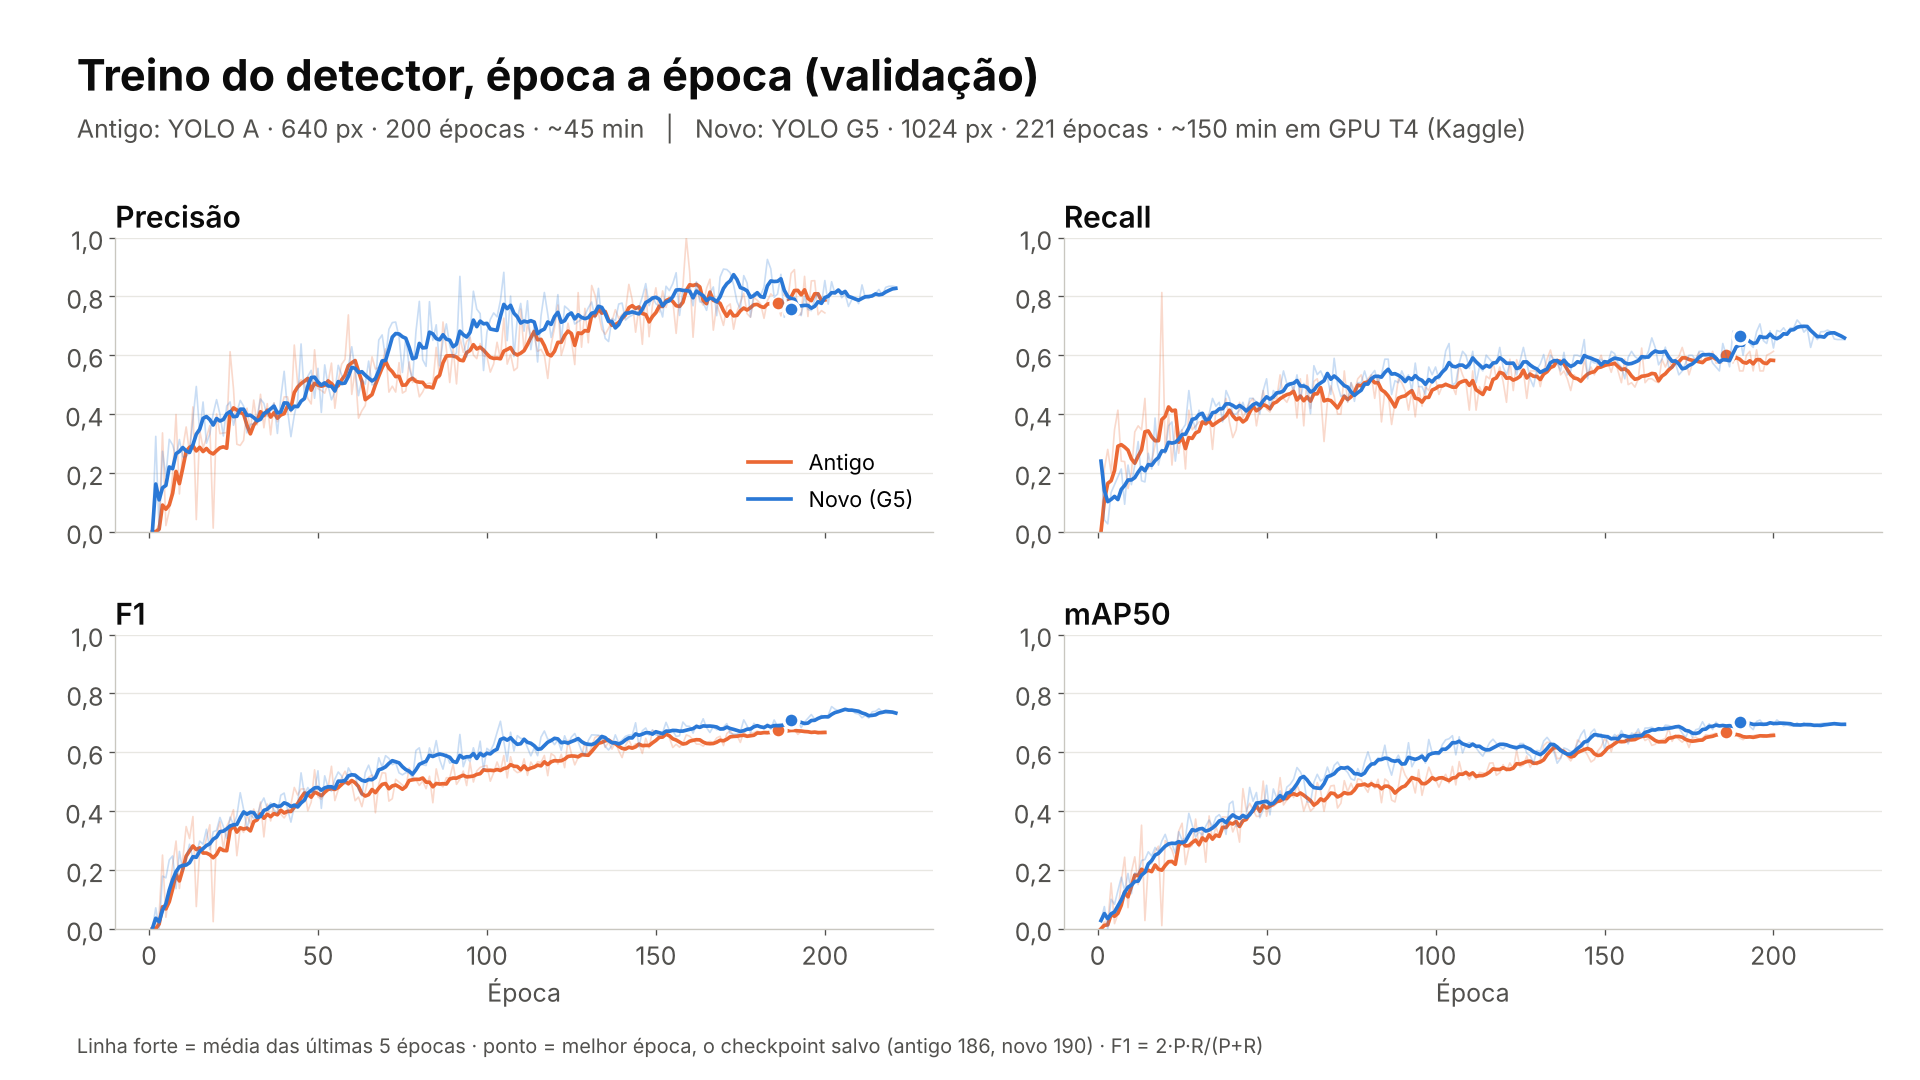

In [3]:
Img("resultados/figuras/comparacao_final/05_treino_yolo_epocas.png", width=1000)

**G5** (YOLOv8s-P2, 1024 px, augmentação para objetos pequenos) teve o melhor critério na validação.

## 2. Integração do G5 ao fluxo (detector → recorte → ConvNeXt)

In [4]:
fe = json.load(open("resultados/pipeline/fase_e.json"))
pd.DataFrame({k: {m: v["test"][m] for m in ["MILCO_tp", "MILCO_fp", "MILCO_precisao", "MILCO_recall", "MILCO_f1"]}
              for k, v in {"P4 (YOLO A + TTA)": fe["P4_referencia"], "P6 (YOLO G5)": fe["pipelines"]["P6_yolo_gpu"]}.items()}).T.round(3)

,MILCO_tp,MILCO_fp,MILCO_precisao,MILCO_recall,MILCO_f1
P4 (YOLO A + TTA),54.0,28.0,0.659,0.720,0.688
P6 (YOLO G5),52.0,14.0,0.788,0.693,0.738


## 3. Fusão de detectores

In [5]:
fz = json.load(open("resultados/pipeline/fusao_detectores.json"))
pd.DataFrame({k: {"varredura teste (minas)": v["varredura_test"]["MILCO_tp"], "varredura FP": v["varredura_test"]["MILCO_fp"],
                  "F1 val": v["F1"]["val_score"], "F1 teste": v["F1"]["test_score"], "minas (F1)": v["F1"]["test"]["MILCO_tp"],
                  "FP (F1)": v["F1"]["test"]["MILCO_fp"], "F2 val": v["F2"]["val_score"], "minas (F2)": v["F2"]["test"]["MILCO_tp"],
                  "FP (F2)": v["F2"]["test"]["MILCO_fp"]} for k, v in fz.items()}).T.round(3)

,varredura teste (minas),varredura FP,F1 val,F1 teste,minas (F1),FP (F1),F2 val,minas (F2),FP (F2)
F_G5tta+mosaico_wbf,63.0,136.0,0.737,0.735,50.0,11.0,0.737,59.0,61.0
F_G5tta+mosaico_nms,64.0,197.0,0.645,0.683,57.0,35.0,0.732,60.0,65.0
F_G5tta+Atta_wbf,63.0,78.0,0.774,0.763,53.0,11.0,0.769,58.0,25.0
F_G5tta+mosaico+Atta_wbf,62.0,125.0,0.740,0.762,56.0,16.0,0.740,56.0,16.0


Escolhida pela validação: **G5+TTA ⊕ YOLO A+TTA (WBF)**. Configs: `modelos/pipeline_config_fusao_recall.json` e `modelos/pipeline_config_fusao_equilibrado.json`.

## 4. Fluxos sob a premissa de recall máximo

In [6]:
pd.DataFrame(json.load(open("resultados/pipeline/recall_max.json"))).set_index("fluxo")[["teto_minas", "teto_fp", "minas", "fp", "recall", "precisao", "val_f2"]].round(3)

,teto_minas,teto_fp,minas,fp,recall,precisao,val_f2
fluxo,,,,,,,
"P0 antigo (YOLO A, conf 0,5 fixo)",49,48,36,7,0.480,0.837,0.461
P2 YOLO A+TTA + fusão antiga,51,75,51,49,0.680,0.510,0.618
P3 YOLO A + ConvNeXt,58,63,53,28,0.707,0.654,0.680
P4 YOLO A+TTA + ConvNeXt,58,83,58,47,0.773,0.552,0.749
P5 mosaico 2x2 + ConvNeXt 3 classes,62,166,52,58,0.693,0.473,0.722
P6 YOLO G5 + ConvNeXt,61,50,52,14,0.693,0.788,0.748
P6t YOLO G5+TTA + ConvNeXt,63,66,54,18,0.720,0.750,0.756


## 5. Versão anterior × fluxo atual

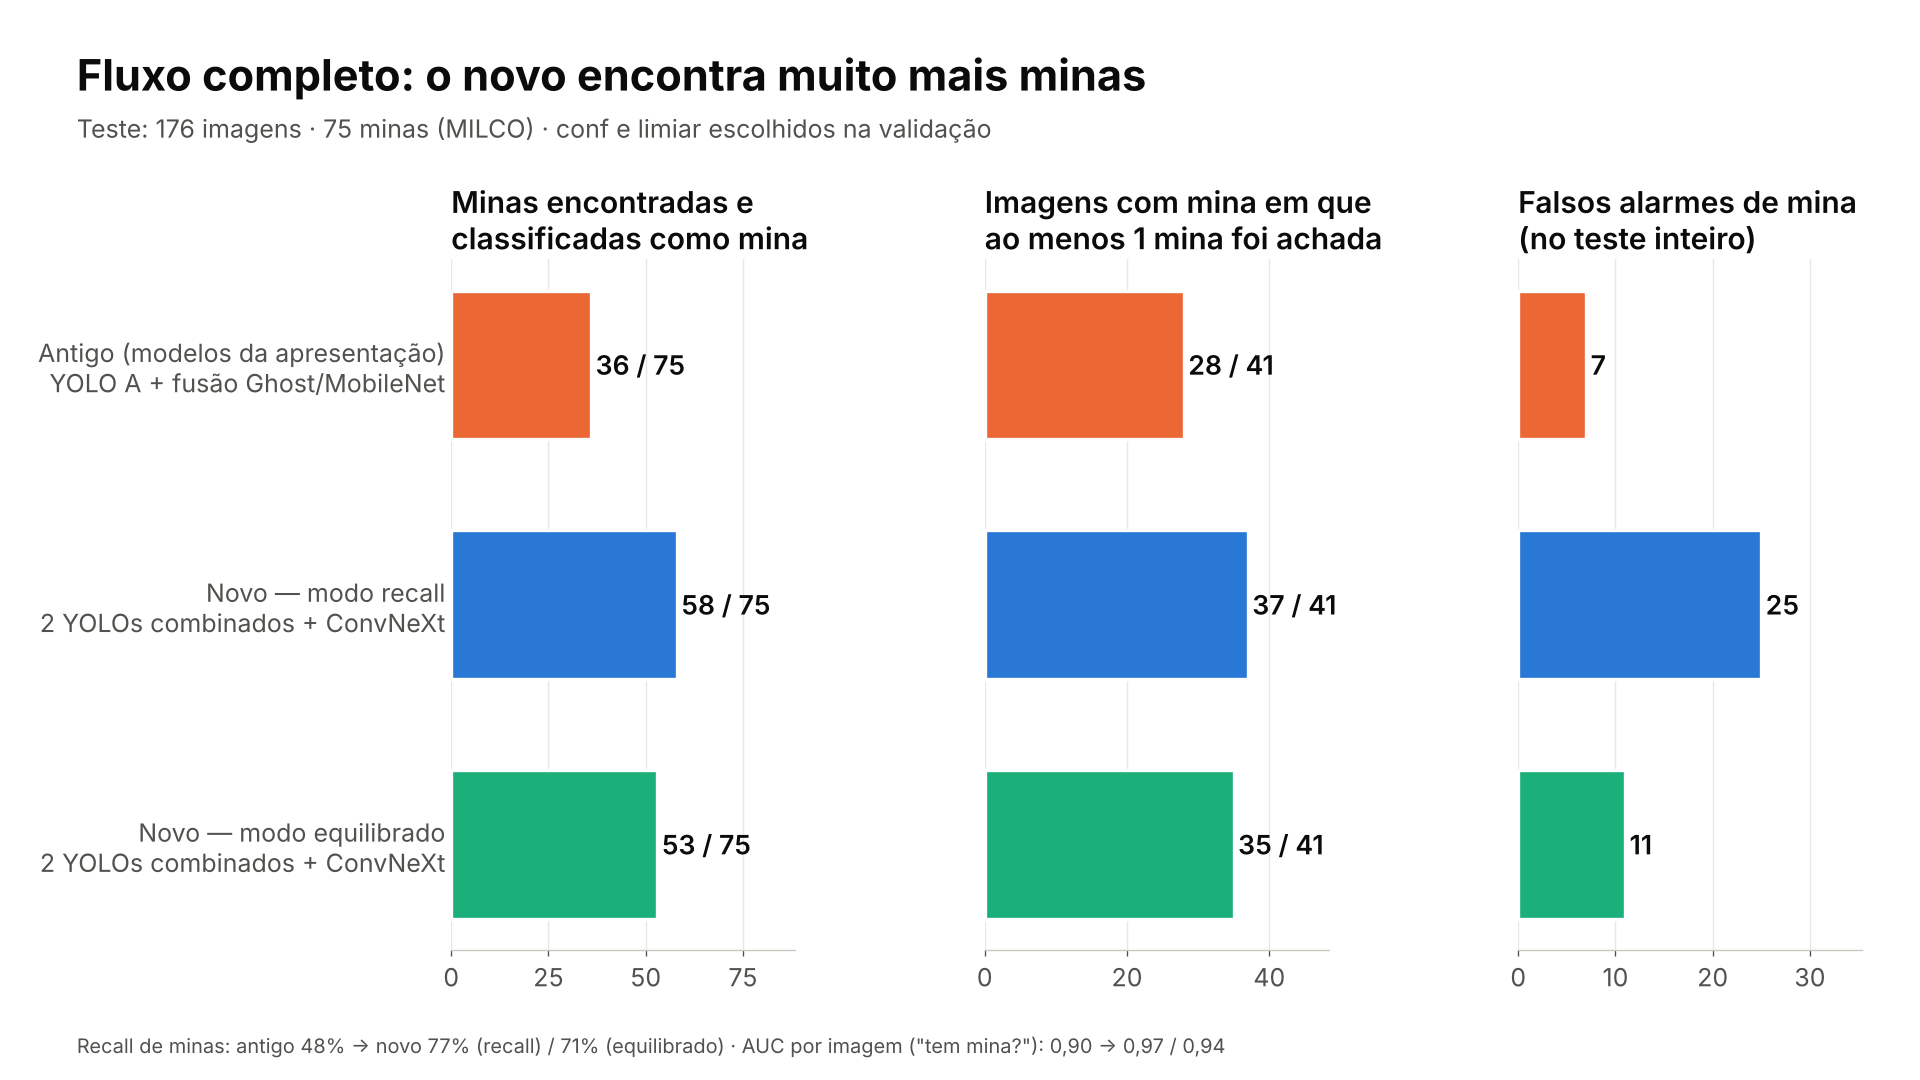

In [7]:
Img("resultados/figuras/comparacao_final/01_minas_encontradas.png", width=1000)

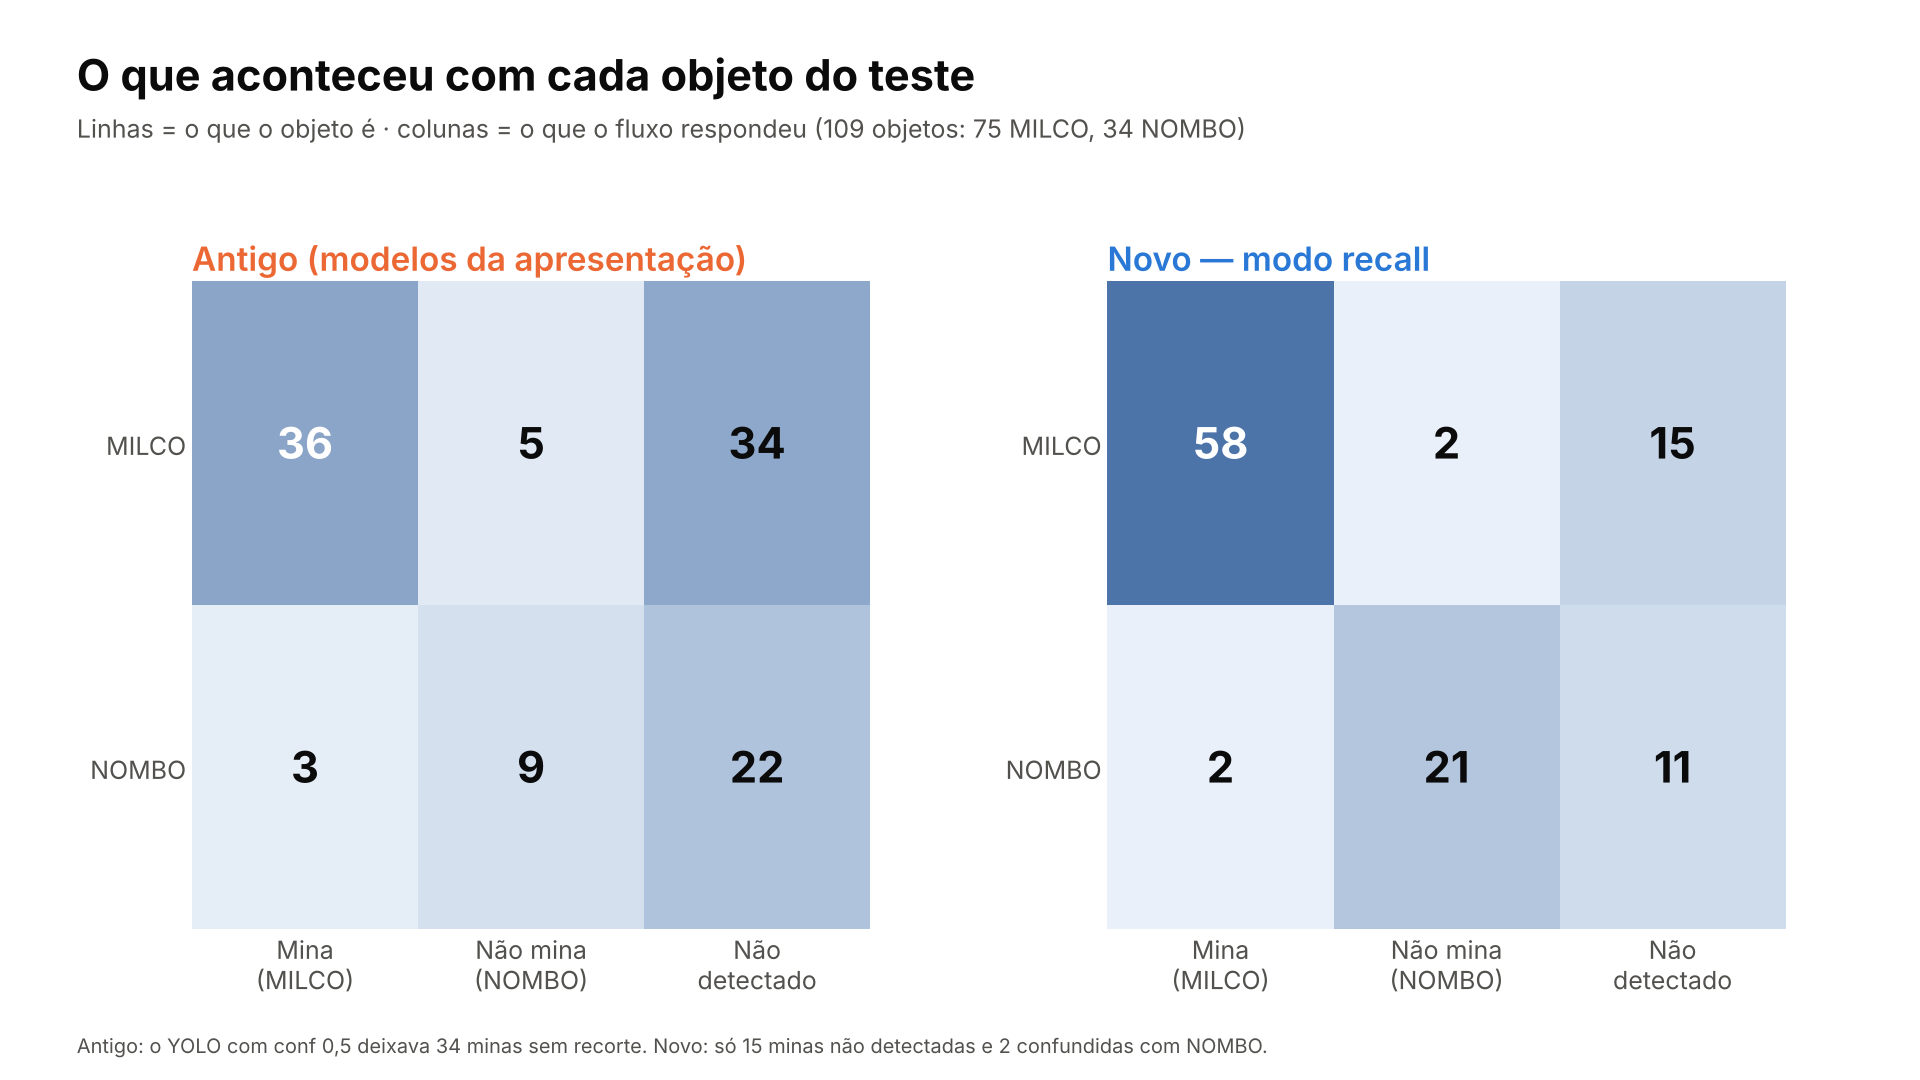

In [8]:
Img("resultados/figuras/comparacao_final/02_destino_dos_objetos.png", width=1000)

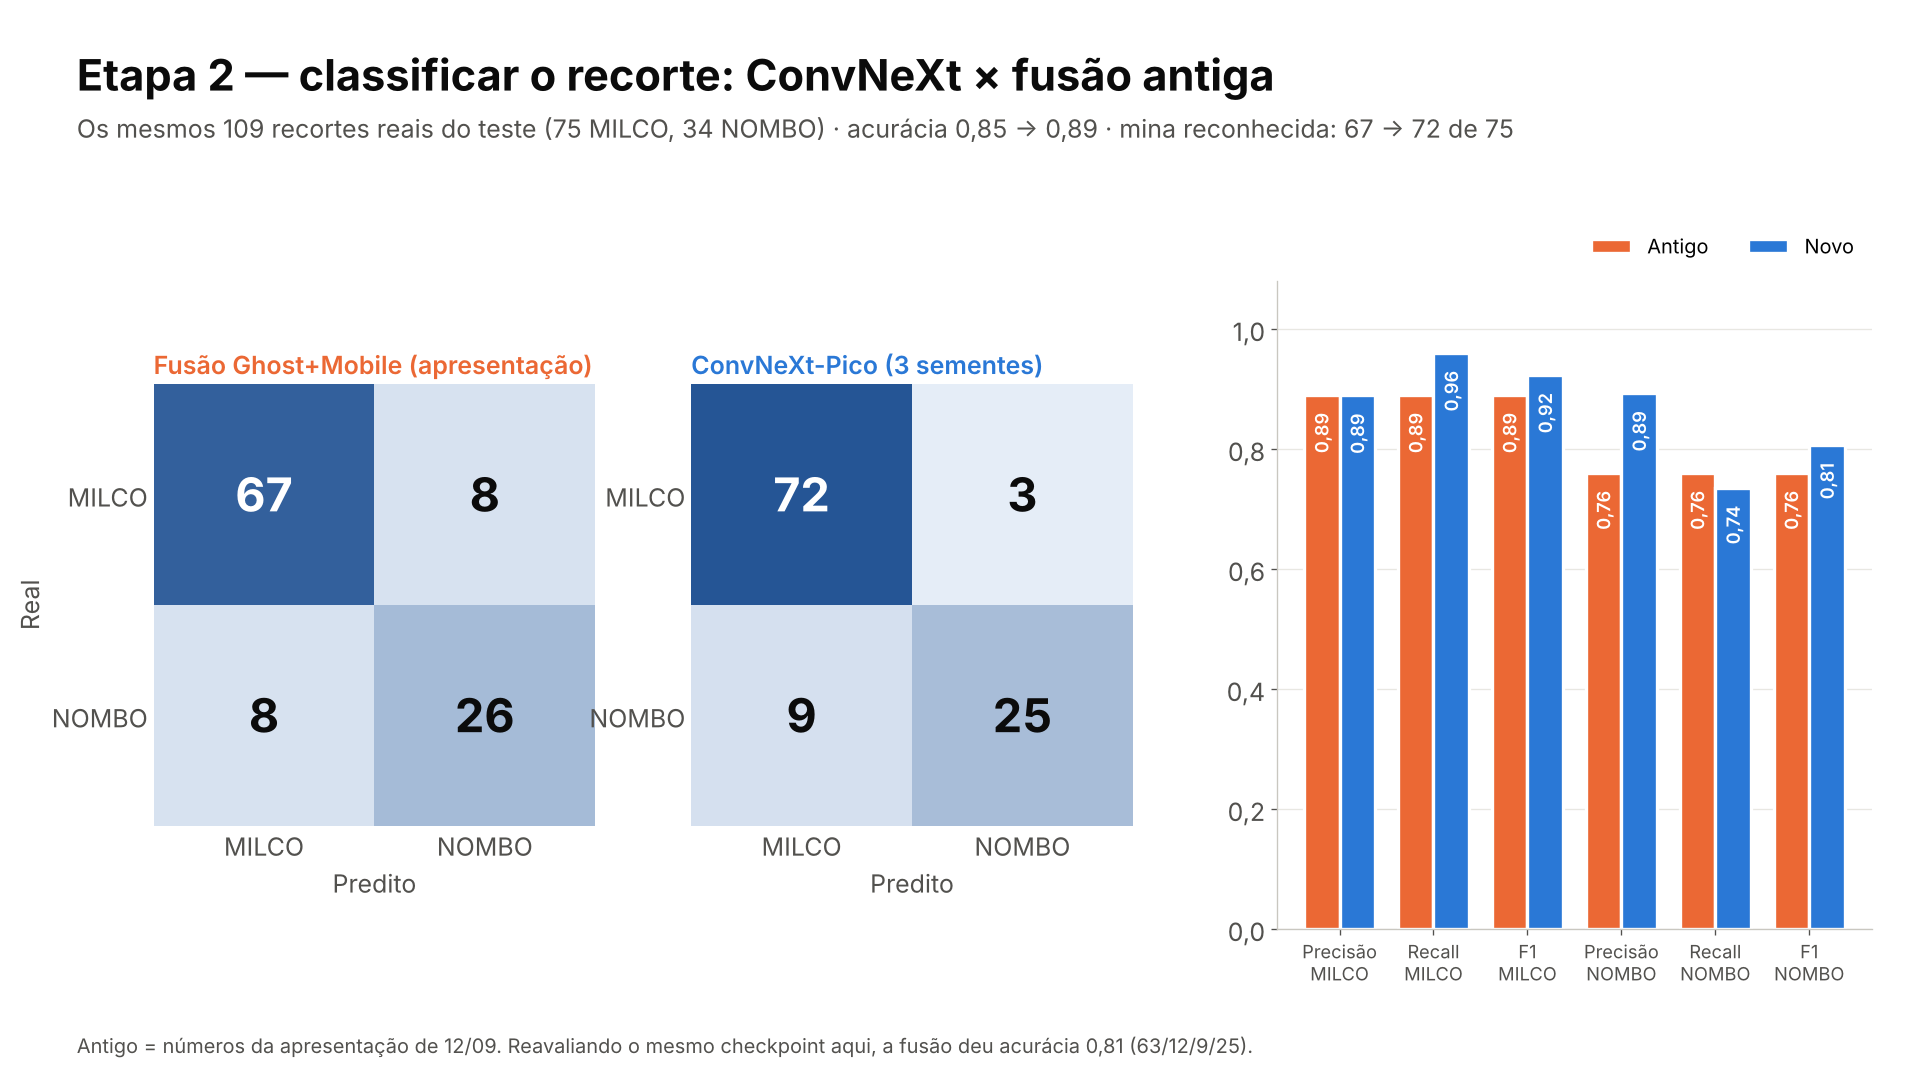

In [9]:
Img("resultados/figuras/comparacao_final/03_classificacao_recortes.png", width=1000)

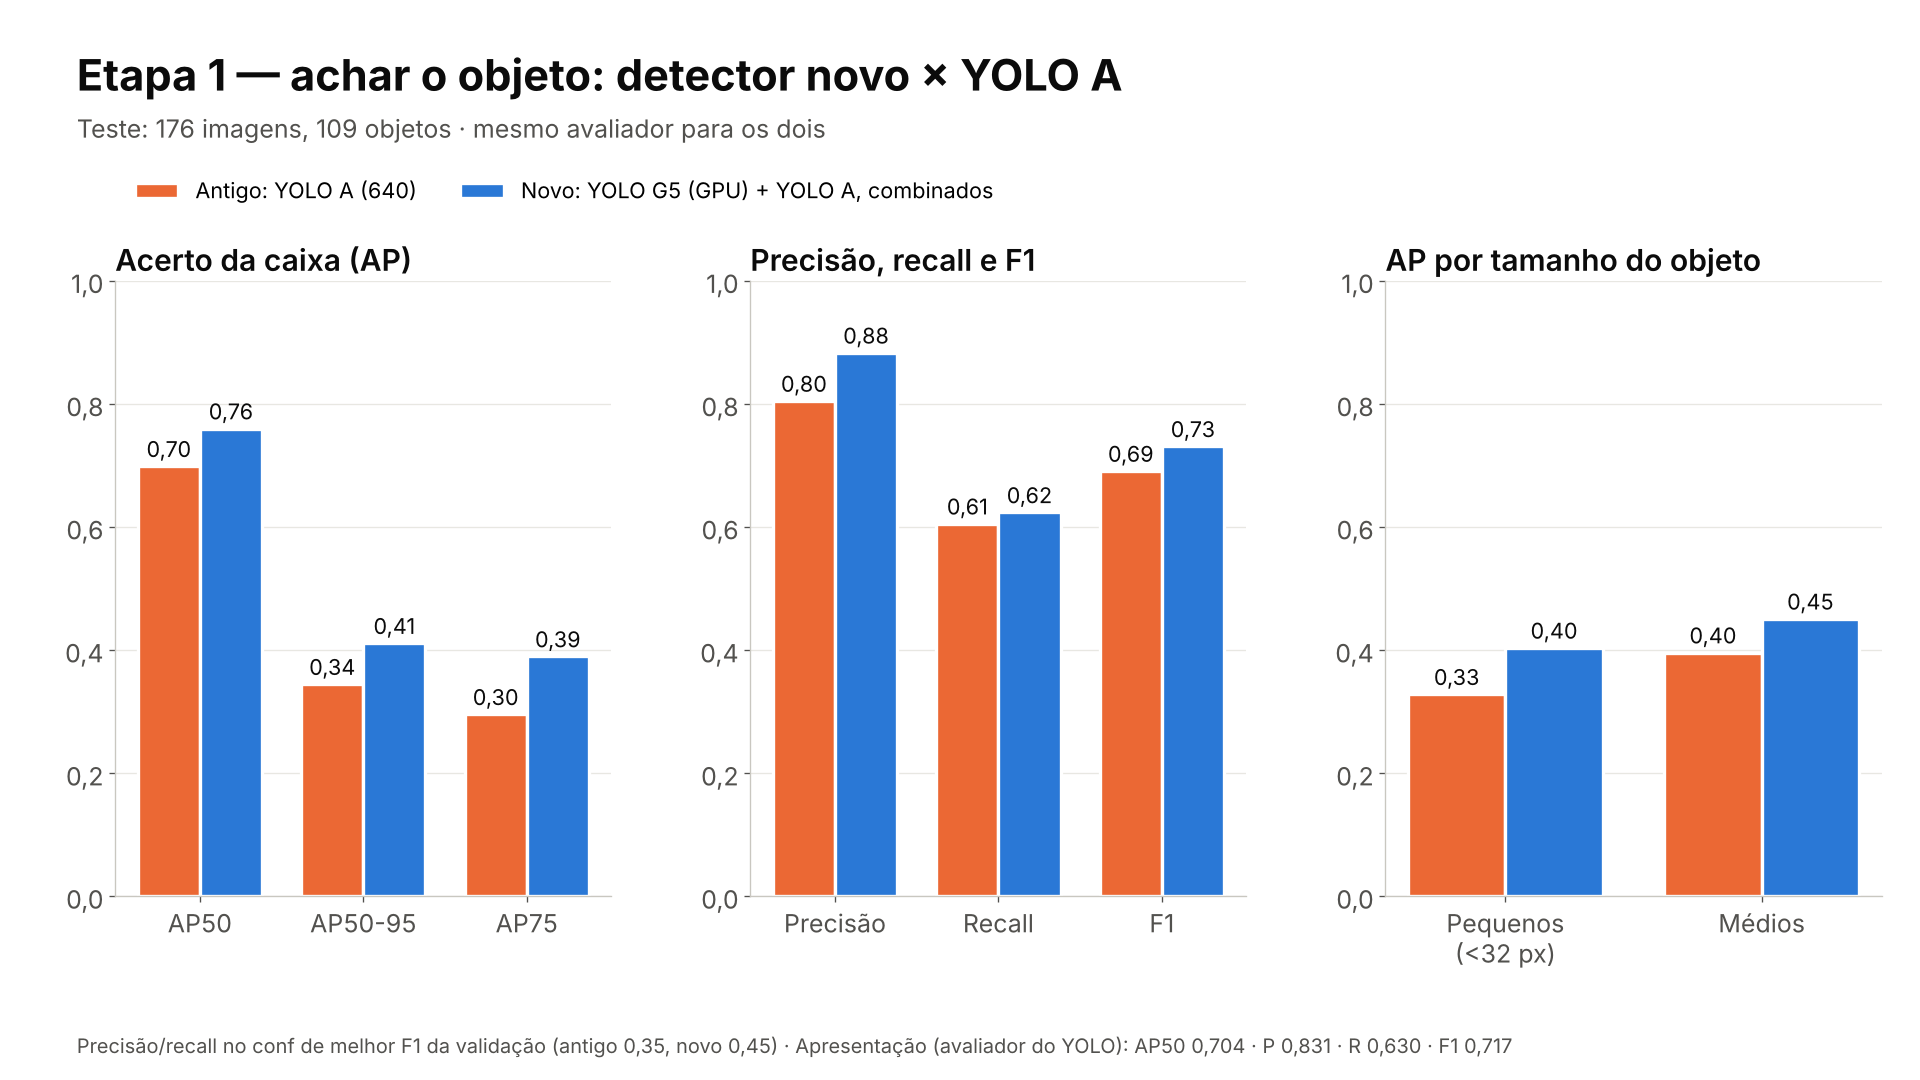

In [10]:
Img("resultados/figuras/comparacao_final/04_detector.png", width=1000)

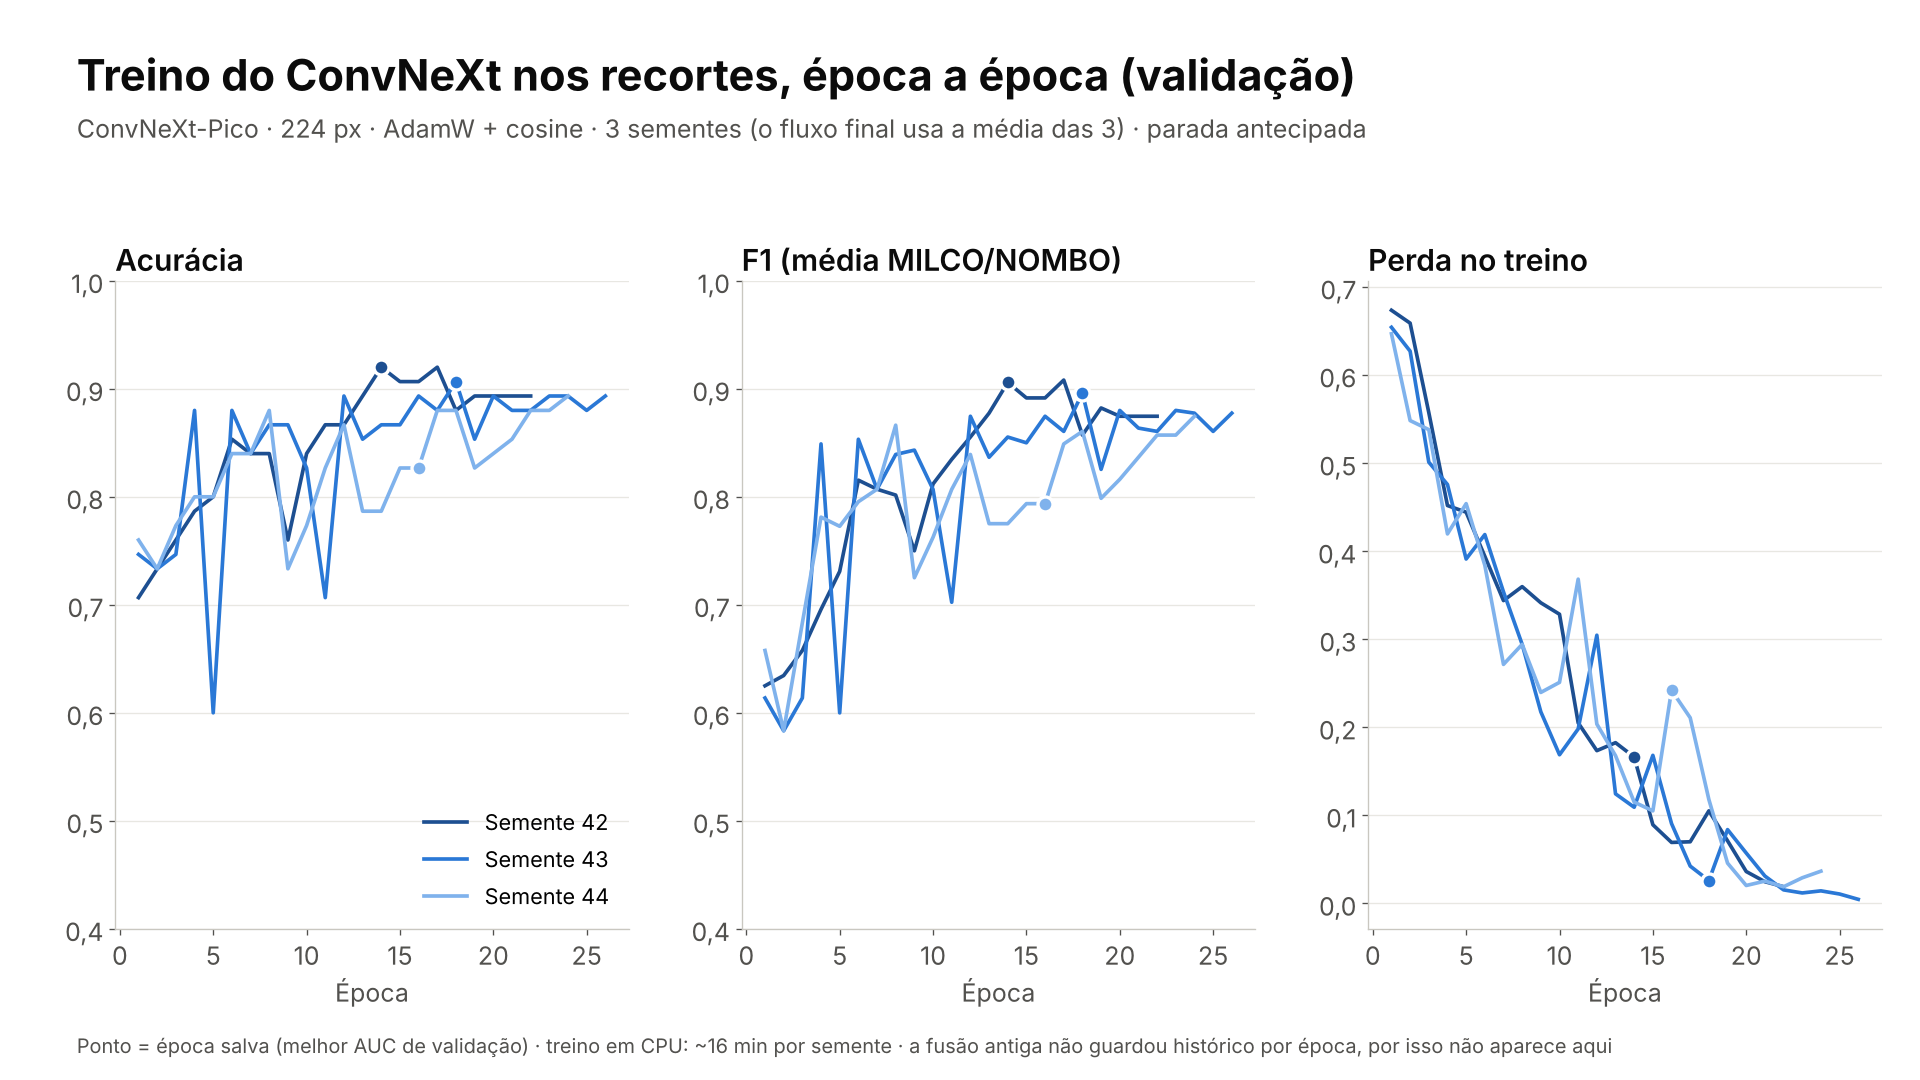

In [11]:
Img("resultados/figuras/comparacao_final/06_treino_convnext_epocas.png", width=1000)